# 3.3 · A machine-learned value score

> **Needs:** the research cache and the database; the second version of notebook 3.1 is the portfolio it is tested in.
>
> **Produces:** registered runs of the families `multi_factor_lo` and `value_only_lo`.

Our value score is a fixed formula: four valuation ratios, each ranked, then averaged. Damon Lee's *Build Your Own AI
Investor* (2nd edition) replaces the formula with a supervised learning model: it is trained on 18 accounting ratios
(the features) and each stock's subsequent one-year return (the target), and learns which combinations of ratios were
associated with high returns.

**The book's method and this replication:**

| Step | The book | Here |
|---|---|---|
| Features | 18 ratios: P/E, P/B, P/S, EV/EBIT, return on equity and on capital, margins, leverage, liquidity, the four Altman ratios | the same 18 ratios, point-in-time at each month end, clipped to the book's bounds |
| Target | the stock's price change over the year after its annual report | the stock's total return over the year after each month end |
| Model | gradient-boosted decision trees: 100 trees, depth 10 | the same, using scikit-learn's faster histogram-based implementation |
| Training sample | **a random half of all company-years** | **only completed years**: refitted every January on data available at the time (walk-forward) |
| Firms near default | excluded (Altman Z'' of 2 or less) | ranked last |
| Portfolio | the top 7, equal weights, held for a year | the same portfolio as notebook 3.1's second version, so only the score differs |

The change that matters is the training sample. A random train/test split lets the model learn from 2018 and then
"predict" 2015: the test set is not out of sample in time, so the backtest suffers from look-ahead bias and
overstates performance (financial returns are autocorrelated across years and stocks, so random splits leak
information). Here every prediction uses a model that could have existed on that date. Training data starts in 2000
(`TRAIN`, the database's first year) and the target needs a year to be observed, so the first model is fitted in
January 2003 and the score exists for every month of the 2004-2024 test.

**Compared over the same dates.** Until 20 November 2026 training began in 2006, so the learned score first existed
in 2007: its books held cash from 2004 to 2006 without saying so - a 0 % return while SPTM gained 33 % - and that cash
was most of the gap reported between the learned and the formula score. A run whose book is empty on a rebalance
date is now refused, and every score here is measured over 2004-2024.

**A steadier learned score** (`ml_value_rank`) is tested beside the book's: the same 18 ratios and walk-forward, but
it predicts each stock's *rank* among the month's members a year on (not its raw return, which a few shares that
tripled or failed and the market's own year dominate), with shallow, regularised trees averaged over five seeds - so
small changes to its inputs do not upend it, as reruns of the book's model did.

The book's own portfolio (seven stocks held for a year) is not replicated: with one decision date a year there would
be one training date a year and no model before 2015. Holding the portfolio construction fixed makes the score the
only difference between the strategies compared.

In [1]:
from dataclasses import replace

import pandas as pd
from IPython.display import display

from equity_research.analytics.indices import vendor_returns
from equity_research.data.cache import ResearchCache
from equity_research.data.universe import load_universe_data
from equity_research.strategies import factors as fx
from equity_research.strategies import learned_value as ml
from equity_research.strategies.factor_strategy import StrategyConfig, factor_scores, run_strategy
from research_core import charts
from research_core.analytics.performance.metrics import decile_returns
from research_core.analytics.performance.tracking import calendar_years
from research_core.data.db.engine import get_engine

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")

charts.style()
cache = ResearchCache()
engine = get_engine()
# The composite score is the weighted mean of these factors' z-scores. Only the ratios matter, and any factor
# run_strategy knows can be added (its error lists them). Equal weights are the notebook's registered trials; any
# change is a new trial, so choose the weights before seeing the results.
FACTOR_WEIGHTS = {"value": 1.0, "quality": 1.0, "momentum": 1.0, "low_vol": 1.0, "issuance": 1.0}
second = StrategyConfig(
    family="multi_factor_lo",
    universe="SP1500",
    start="2004-01-01",
    end="2024-12-31",
    factors=tuple(FACTOR_WEIGHTS.items()),
    enter=0.30,
    exit_=0.40,
    long_only=True,
    beta_neutral=False,
    weighting="market_cap",
)
# the learned scores train from here (the database's first year), so they exist for every month of the test
TRAIN = "2000-01-01"
data = load_universe_data(cache, second.universe, TRAIN, second.end)
sptm = vendor_returns(cache, "SPTM", total=True)

left out 1078 facts of 2 companies in ['GBP']


## Decile comparison of the two scores

Each month the constituents are sorted into deciles by each score, and each decile's equal-weighted next-month return
is compared with the universe average (before costs), from 2004. The learned scores exist only where a model had
already been fitted; a company in Altman's distress zone ranks last.

In [2]:
members_on = data.members.reindex(data.rebalances)
learned_raw = ml.learned_value(data.ratios, data.returns, data.members, data.rebalances)
steady_raw = ml.learned_value_rank(data.ratios, data.returns, data.members, data.rebalances)
scores = {
    "plain value": factor_scores(data, "value"),
    "learned value": fx.cross_sectional_z(learned_raw, members_on),
    "steadier learned value": fx.cross_sectional_z(steady_raw, members_on),
}
after = data.rebalances >= pd.Timestamp(second.start)
deciles = {name: decile_returns(s.loc[after], data.returns, data.members) for name, s in scores.items()}
display(pd.DataFrame({name: d["excess"] for name, d in deciles.items()}).T.style.format("{:+.1%}"))
print("Top tenth t:", {name: round(float(d.loc[10, "t"]), 1) for name, d in deciles.items()})
alike = scores["learned value"].loc[after].corrwith(scores["plain value"].loc[after], axis=1).mean()
print(f"How alike the two scores are (average correlation across companies each month): {alike:+.2f}")
covered = (learned_raw.notna() & members_on).sum(axis=1) / members_on.sum(axis=1)
print("Members with a learned score, each December (the test starts in 2004):")
display(covered[covered.index.month == 12].to_frame("covered").T.style.format("{:.0%}"))

decile,1,2,3,4,5,6,7,8,9,10
plain value,-2.2%,-2.1%,-0.7%,-0.8%,-1.0%,+0.7%,-0.6%,+1.3%,+2.6%,+2.8%
learned value,-0.5%,-2.6%,-0.7%,-0.6%,-0.7%,-0.9%,+0.3%,+0.6%,+2.5%,+2.9%
steadier learned value,-2.5%,+0.3%,+1.2%,-0.3%,+0.2%,-1.0%,+0.8%,+0.1%,+0.6%,+0.9%


Top tenth t: {'plain value': 1.2, 'learned value': 1.2, 'steadier learned value': 0.7}
How alike the two scores are (average correlation across companies each month): +0.51
Members with a learned score, each December (the test starts in 2004):


,2000-12-29 00:00:00,2001-12-31 00:00:00,2002-12-31 00:00:00,2003-12-31 00:00:00,2004-12-31 00:00:00,2005-12-30 00:00:00,2006-12-29 00:00:00,2007-12-31 00:00:00,2008-12-31 00:00:00,2009-12-31 00:00:00,2010-12-31 00:00:00,2011-12-30 00:00:00,2012-12-31 00:00:00,2013-12-31 00:00:00,2014-12-31 00:00:00,2015-12-31 00:00:00,2016-12-30 00:00:00,2017-12-29 00:00:00,2018-12-31 00:00:00,2019-12-31 00:00:00,2020-12-31 00:00:00,2021-12-31 00:00:00,2022-12-30 00:00:00,2023-12-29 00:00:00,2024-12-31 00:00:00
covered,0%,0%,0%,99%,99%,99%,99%,99%,99%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%,100%


## Inside a portfolio

First each score on its own, in the same portfolio as notebook 3.1's second version (the top 30 % by score, held until
it leaves the top 40 %, cap-weighted), all over 2004-2024. Then the second version itself, with the learned score in
place of the formula value score. Every run is registered; the value-only portfolios form a family of trials. The
learned runs train from 2000 (`train_from`), a setting of their own: they are new trials, not repeats of the runs
that held cash until 2007.

In [3]:
alone = replace(second, family="value_only_lo")
learned_five = tuple(("ml_value", w) if n == "value" else (n, w) for n, w in FACTOR_WEIGHTS.items())
configs = {
    "plain value alone": replace(alone, factors=(("value", 1.0),)),
    "learned value alone": replace(alone, factors=(("ml_value", 1.0),), train_from=TRAIN),
    "steadier learned value alone": replace(alone, factors=(("ml_value_rank", 1.0),), train_from=TRAIN),
    "second version (plain value)": second,
    "second version, learned value instead": replace(second, factors=learned_five, train_from=TRAIN),
}
runs = {name: run_strategy(cache, cfg, engine=engine) for name, cfg in configs.items()}
ACTIVE = {
    "cagr": "{:.1%}",
    "sharpe": "{:.2f}",
    "max_drawdown": "{:.0%}",
    "beta": "{:.2f}",
    "alpha": "{:+.1%}",
    "active_return": "{:+.1%}",
    "tracking_error": "{:.1%}",
    "information_ratio": "{:+.2f}",
    "deflated_active_sharpe": "{:.0%}",
    "turnover": "{:.1f}",
}
display(pd.DataFrame({name: r.metrics for name, r in runs.items()}).T[list(ACTIVE)].style.format(ACTIVE))
print("Registered as research runs", {name: r.run_id for name, r in runs.items()})
print("Trials so far:", {cfg.family: runs[name].metrics["trials"] for name, cfg in configs.items()})

left out 1078 facts of 2 companies in ['GBP']


left out 1078 facts of 2 companies in ['GBP']


left out 1078 facts of 2 companies in ['GBP']


left out 1078 facts of 2 companies in ['GBP']


left out 1078 facts of 2 companies in ['GBP']


,cagr,sharpe,max_drawdown,beta,alpha,active_return,tracking_error,information_ratio,deflated_active_sharpe,turnover
plain value alone,10.0%,0.54,-57%,1.10,-0.8%,-0.3%,7.8%,+0.03,19%,1.4
learned value alone,8.8%,0.51,-59%,1.08,-2.0%,-1.4%,5.1%,-0.21,2%,2.9
steadier learned value alone,9.0%,0.54,-59%,0.98,-0.9%,-1.2%,3.7%,-0.32,0%,1.7
second version (plain value),10.5%,0.67,-45%,0.85,+1.6%,+0.2%,4.1%,-0.01,3%,1.2
"second version, learned value instead",10.7%,0.68,-45%,0.86,+1.6%,+0.3%,3.8%,+0.02,3%,1.2


Registered as research runs {'plain value alone': 197, 'learned value alone': 198, 'steadier learned value alone': 199, 'second version (plain value)': 200, 'second version, learned value instead': 201}
Trials so far: {'value_only_lo': 6, 'multi_factor_lo': 21}


Each year: the strategy's return minus SPTM's


,plain value alone,learned value alone,steadier learned value alone,second version (plain value),"second version, learned value instead"
trade_date,,,,,
2004,+12.0%,+4.3%,+7.0%,+1.2%,+0.0%
2005,+8.8%,-0.5%,-1.7%,+0.4%,-0.3%
2006,+5.2%,+1.4%,-0.4%,+1.2%,+0.2%
2007,-0.9%,-3.5%,-6.1%,-0.8%,+0.4%
2008,+0.8%,-1.4%,-2.9%,+9.1%,+9.7%
2009,+7.9%,+2.3%,-1.9%,-7.3%,-7.5%
2010,+2.0%,+2.9%,-1.8%,-5.4%,-4.5%
2011,-2.7%,-1.9%,+4.3%,+7.4%,+8.6%
2012,+2.9%,+2.4%,-2.3%,-0.4%,-1.5%


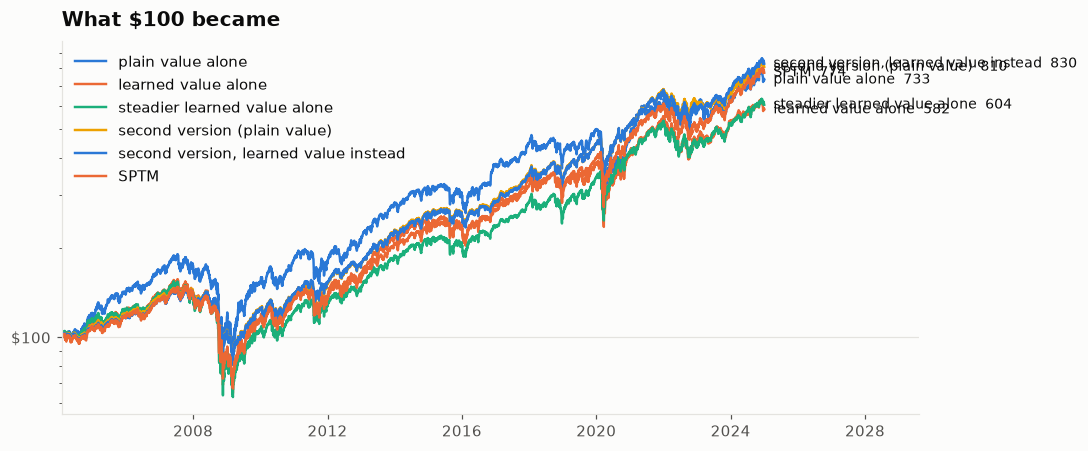

In [4]:
fig = charts.growth({name: r.backtest.net for name, r in runs.items()} | {"SPTM": sptm}, "What $100 became")
ahead = pd.DataFrame(
    {
        name: calendar_years({name: r.backtest.net, "SPTM": sptm}).pipe(lambda y, n=name: y[n] - y["SPTM"])
        for name, r in runs.items()
    }
)
print("Each year: the strategy's return minus SPTM's")
display(ahead.style.format("{:+.1%}", na_rep=""))

## Findings

Printed from the results above (they used to be typed, and fell out of step with the tables when the data changed).

In [5]:
from IPython.display import Markdown

m = {name: r.metrics for name, r in runs.items()}
top = {name: d.loc[10] for name, d in deciles.items()}
best = max(m, key=lambda k: m[k]["deflated_active_sharpe"])


def alone_line(name: str) -> str:
    """One score alone, in a phrase: its return, against SPTM, its drawdown and turnover."""
    x = m[name]
    return (
        f"{name}: {x['cagr']:.1%} a year, {x['active_return']:+.1%} against SPTM (information ratio "
        f"{x['information_ratio']:+.2f}), maximum drawdown {x['max_drawdown']:.0%}, turnover {x['turnover']:.1f}"
    )


plain_five, learned_five_run = m["second version (plain value)"], m["second version, learned value instead"]
lines = [
    "* **Each score alone, over the same dates (2004-2024):** "
    + "; ".join(alone_line(n) for n in ("plain value alone", "learned value alone", "steadier learned value alone"))
    + ".",
    "* **Deciles:** the top tenth's excess return a year - "
    + ", ".join(f"{name} {t['excess']:+.1%} (t {t['t']:.1f})" for name, t in top.items())
    + f". The learned score's correlation with formula value is {alike:+.2f}: it mixes valuation with profitability, "
    "leverage and liquidity, so it is closer to a quality score than a value score.",
    f"* **In the five-factor portfolio:** with formula value {plain_five['cagr']:.1%} a year, "
    f"{plain_five['active_return']:+.1%} against SPTM; with the learned score instead {learned_five_run['cagr']:.1%}, "
    f"{learned_five_run['active_return']:+.1%}.",
    f"* **Evidence:** the best deflated active Sharpe ratio is {m[best]['deflated_active_sharpe']:.0%} ({best}), "
    "far below the 95 % that would count as evidence; the registry counts only trials since 15 November 2026.",
]
display(Markdown("\n".join(lines)))

* **Each score alone, over the same dates (2004-2024):** plain value alone: 10.0% a year, -0.3% against SPTM (information ratio +0.03), maximum drawdown -57%, turnover 1.4; learned value alone: 8.8% a year, -1.4% against SPTM (information ratio -0.21), maximum drawdown -59%, turnover 2.9; steadier learned value alone: 9.0% a year, -1.2% against SPTM (information ratio -0.32), maximum drawdown -59%, turnover 1.7.
* **Deciles:** the top tenth's excess return a year - plain value +2.8% (t 1.2), learned value +2.9% (t 1.2), steadier learned value +0.9% (t 0.7). The learned score's correlation with formula value is +0.51: it mixes valuation with profitability, leverage and liquidity, so it is closer to a quality score than a value score.
* **In the five-factor portfolio:** with formula value 10.5% a year, +0.2% against SPTM; with the learned score instead 10.7%, +0.3%.
* **Evidence:** the best deflated active Sharpe ratio is 19% (plain value alone), far below the 95 % that would count as evidence; the registry counts only trials since 15 November 2026.

**Earlier runs.** Until 20 November 2026 the learned books trained from 2006 and held cash for 2004-2006, and the
findings typed here said the learned score beat formula value (13.5 % against 11.2 % a year): with the cash years in
the record it returned 8.3 % against 10.0 %, and over the same dates the comparison is the one above. Reruns of the
book's model on slightly different data moved it by two points a year (14.5 % and 0.4 % ahead of SPTM on 14 November,
0.5 % behind on 17 November) - the reason for the steadier variant. An earlier run still showed the learned score
1.4 % a year ahead inside the portfolio; that was a data error (LSEG's restated share counts made Alphabet's market
value twenty times too large, a third of the portfolio in 2015), and market values now use each share class's own
point-in-time count.

## Glossary

* **Supervised learning** - fitting a model that maps inputs (features) to a known outcome (the target) from
  examples, instead of specifying the rule by hand.
* **Gradient-boosted trees** - an ensemble of shallow decision trees fitted sequentially, each one fitted to the
  residual errors of the ensemble so far; flexible enough to capture non-linear effects and interactions.
* **Walk-forward validation** - training only on data available before each prediction date, as the model would have
  had to be used in practice.
* **Overfitting** - a model that fits noise in its training data and so performs worse on new data than in sample.
* **Altman Z''** - Altman's (1995) bankruptcy-prediction score for non-manufacturers, a weighted sum of four
  balance-sheet ratios; 2 or less is the distress zone.
* **Active return**, **information ratio**, **deflated Sharpe ratio** - see notebook 3.1.